### PDAC and neural invasion - regions, niches and high vs low NI (mp_pdac02)

**Paper**: Chen MM, Gao Q, Ning H, Chen K, Gao Y, Yu M, Liu CQ, Zhou W, Pan J, Wei L, Dou W, Zhang D, Zhu L, Zhang Q, Chen R, Zhang Z. *Integrated single-cell and spatial transcriptomics uncover distinct cellular subtypes involved in neural invasion in pancreatic cancer.* Cancer Cell. 2025 Sep 8;43(9):1656-1676.e10. doi: [10.1016/j.ccell.2025.06.020](https://doi.org/10.1016/j.ccell.2025.06.020). PMID: 40680743.

Code: [github.com/PDAC-zhanglab/PDAC](https://github.com/PDAC-zhanglab/PDAC) (R figure scripts; copy in pdac/data/github_PDAC-zhanglab) - Data: GEO SuperSeries [GSE278694](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278694) = [GSE278687](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278687) (Visium, 21 sections) + [GSE278688](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278688) (scRNA) + [GSE278689](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278689) (FFPE snRNA) + GSE300435 (scTCR); raw reads GSA HRA008568.

It continues **mp_pdac01_prepare.ipynb**: the regions computed there (**pdac01_region_labels.tsv**: Leiden clusters of the cell-type shares of the 21 sections, named after the paper's 12 niches) are read, not recomputed, and studied as in the paper's Figures 1-3: which cell types define each niche, how niches and cell types differ between **low-NI** and **high-NI** tumours, the malignant subtypes and their diversity.

#### Libs: **src/libs**

- **single_cell_lib**
  - Class **SingleCell**: generic Scanpy, Squidpy, cell2location and LIANA methods
  - **DEFAULT_PARAMS**
- **single_cell_pdac_lib** (new)
  - Class **SingleCellPDAC(SingleCell)**: PDAC methods (sections, NI status and platforms, re-derived subclusters, RCTD / cell2location abundances, regions named after the paper's niches, sections as replicates for high vs low NI, nerve spots / invasion / rings)
  - **PDAC_PARAMS**, **PDAC_SUBCLUSTERS** (marker sets of the paper's subclusters), **PDAC_GENES** (26 PDAC / NI genes), **PDAC_NI_GENES**, **PDAC_NERVE_GENES**, **PAPER_NICHES**, **PDAC_FILES** (one file registry per notebook: 'pdac01' ... 'pdac04')

**Programs: src/programs**: pdac_build_h5ad.py (GEO -> h5ad), pdac_reference_subclusters.py (subclusters), run_rctd_pdac.R (RCTD), run_c2l_pdac.py (cell2location, GPU).

| section | content |
|---|---|
| 1 | spots, abundances and regions of mp_pdac01 |
| 2 | region table: size, sections, platforms, cell types, niche |
| 3 | Figure 1F: relative cell-type proportion in each niche (and region) |
| 4 | niches on the sections (Figure 1D right) |
| 5 | Figures 2E / 3D: niche share per section, low vs high NI (all sections; CytAssist only) |
| 6 | Figure 3C: PCA of the sections on niche shares |
| 7 | Figure 3B: TLS cell types and other cell types, low vs high NI |
| 8 | Figures 2C / 2J: malignant subtypes, pure spots, composition and Shannon diversity per section |
| 9 | co-occurrence of cell types across sections (Figure 3I analogue) |
| 10 | PDAC / NI genes per region (dot plot); NI-related gene score (Figure 2M on Visium) |
| 11 | interactive region maps |

Figures and tables have the prefix **pdac02_**.

### Critique of the analysis and how it is handled

1. **21 sections, 17 patients**: sections are the replicates (PA04, PA05 and PA11 have two sections each, so p-values are slightly optimistic); effect sizes and the per-section points are shown with every test.
2. **Platform confound**: all 5 low-NI sections are CytAssist, all FF / FFPE-v1 sections high-NI. Every high vs low test is repeated on the 12 CytAssist sections (5 low vs 7 high); a difference that disappears there is not interpretable as NI biology.
3. **Ridge plots of the paper** summarise the same 5 vs 16 values per niche; here box + points (marker = platform) show them directly.
4. **Niche names are inferred** from composition (assign_niches); the paper's 12 niches were assigned with the H&E and are not public. Malignant regions are named after their dominant subtype ('N07-10_Malignant (D04_Ductal-GABRP)'), since the paper's N07-N10 numbering is not published (except N10 = D02_Ductal-APOA2). 'mixed' regions have no clear niche; 'N00_unassigned' = spots RCTD could not deconvolve (< 100 UMIs).
5. **Deconvolution source**: RCTD (the paper's method) or cell2location (GPU map); the tables carry it in **abundance_source**.

## Loading packages

In [1]:
import os, sys
from pathlib import Path
from importlib.metadata import version
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import gc

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42          # editable text in PDFs
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 90}   # inline display only; files are saved at 300 dpi
import plotly.io as pio
pio.renderers.default = "notebook_connected"

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.single_cell_pdac_lib import (SingleCellPDAC, PDAC_PARAMS, PDAC_SUBCLUSTERS, PDAC_GENES, PDAC_NI_GENES,
                                       PDAC_NERVE_GENES, PAPER_NICHES, PDAC_FILES)
from libs.single_cell_lib import cmap_byr, cmap_lbwr
from libs.matplotlib_figure_style import apply_figure_style
from libs.Basic import create_dir

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
pd.set_option('display.max_rows', 200)
print({p: version(p) for p in ['scanpy', 'squidpy', 'anndata', 'plotly']})

{'scanpy': '1.12.4', 'squidpy': '1.8.3', 'anndata': '0.13.4', 'plotly': '7.1.0'}


## Parameters

In [2]:
force=False       # True: recompute every table and redraw every figure (after changing parameters or inputs)
verbose=True

apply_figure_style()
scp = SingleCellPDAC(ROOT0, analysis='pdac02')
root_data, root_figure, root_result = scp.root_data, scp.root_figure, scp.root_result
print(scp)
scp.calc_df_files()

SingleCellPDAC(project='pdac', adata=None, symbol_col='symbol', sample_col='section')
Out[2]: 
                         key  ... exists
0                     visium  ...   True
1                  reference  ...   True
2                   sections  ...   True
3                 visium_raw  ...   True
4                    geo_dir  ...   True
5                geo_samples  ...   True
6                     sc_dir  ...   True
7                     sn_dir  ...   True
8                 st_tar_dir  ...   True
9          subcluster_labels  ...   True
10                  rctd_dir  ...   True
11              rctd_weights  ...   True
12               c2l_ref_dir  ...   True
13               c2l_map_dir  ...   True
14                   c2l_map  ...  False
15                signatures  ...  False
16             region_labels  ...   True
17             region_niches  ...   True
18               region_info  ...  False
19             lineage_table  ...   True
20           nerve_overrides  ...  False
21 

,key,root,name,path,exists
0,visium,data,pdac_visium_21sections.h5ad,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_visium_21sections.h5ad,True
1,reference,data,pdac_sc_sn_reference.h5ad,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_sc_sn_reference.h5ad,True
2,sections,data,pdac_sections.tsv,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_sections.tsv,True
3,visium_raw,data,visium,/home/flavio/uv/cell_cell_communication/pdac/data/visium,True
4,geo_dir,data,geo,/home/flavio/uv/cell_cell_communication/pdac/data/geo,True
5,geo_samples,data,geo/GSE278694_samples_soft.txt,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278694_samples_soft.txt,True
6,sc_dir,data,geo/GSE278688,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278688,True
7,sn_dir,data,geo/GSE278689,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278689,True
8,st_tar_dir,data,geo/GSE278687/raw,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278687/raw,True
9,subcluster_labels,result,pdac01_reference_subclusters.tsv,/home/flavio/uv/cell_cell_communication/pdac/results/pdac01_reference_subclusters.tsv,True


### 1. Spots, abundances and the regions of mp_pdac01

In [3]:
df_regions = scp.read_tsv('region_labels', verbose=verbose)
source = df_regions['abundance_source'].iloc[0]
print("regions of mp_pdac01 made with:", source)
adata_vis = scp.read_h5ad('visium', set_self=False, verbose=verbose)
adata_vis = scp.remove_mt_genes(adata_vis)
if source == 'c2l':
    a_map = scp.read_h5ad_slots('c2l_map', skip=('layers',))
    adata_vis.obsm['q05_cell_abundance_w_sf'] = pd.DataFrame(a_map.obsm['q05_cell_abundance_w_sf'], index=a_map.obs_names).loc[adata_vis.obs_names]
    adata_vis.uns['mod'] = a_map.uns['mod']; del a_map
scp.calc_qc_metrics(adata_vis)
df_abund = scp.get_abundance(adata_vis, source=source)
df_share = scp.shares(df_abund)
d = df_regions.set_index('barcode').loc[adata_vis.obs_names]
for c in ('region_cluster', 'region_label', 'region_name', 'niche'):
    adata_vis.obs[c] = pd.Categorical(d[c].astype(str).values)
names = dict(zip(d.region_label.astype(str), d.region_name.astype(str)))
regions = list(adata_vis.obs['region_label'].cat.categories)
niches = sorted(adata_vis.obs['niche'].unique())
sections_rep = scp.representative_sections()
df_sections = scp.section_table(adata_vis)
print(adata_vis.shape, '|', len(regions), 'regions |', len(niches), 'niches |', source, df_abund.shape)

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac01_region_labels.tsv (81,846 rows)
regions of mp_pdac01 made with: rctd
Reading /home/flavio/uv/cell_cell_communication/pdac/data/pdac_visium_21sections.h5ad
(81846, 36588) | 28 regions | 15 niches | rctd (81846, 42)


### 2. Region table

Per region: spots, sections, platforms, median UMIs, top cell types by share and by enrichment, the niche (mp_pdac01).

In [4]:
df_region_summary = scp.calc_df_region_summary(adata_vis, df_share, names, fname='tsv_region_summary', force=force, verbose=verbose)
df_region_summary

Table saved ((28, 10)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_region_summary.tsv'
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac02_region_summary.tsv (28 rows)
Out[4]: 
   region_label  ...                                                                                top_enriched
0           R00  ...                         D01_Ductal-CFTR (10.5x), F04_hspCAF-HSPA1A (3.6x), Endocrine (2.5x)
1           R01  ...                         F06_Fibro-MALAT1 (3.1x), M11_Neutrophil-CXCL8 (2.6x), Plasma (2.5x)
2           R02  ...                         Stellate (21.2x), Endothelial (2.2x), F02_Progenitor-CAF-DPT (1.9x)
3           R03  ...                                                B (22.8x), CD4T (9.8x), M04_cDC-LAMP3 (7.0x)
4           R04  ...                S01_Schwann-ABCA8 (27.7x), F07_Fibro-NRP2 (19.0x), S02_Schwann-TGFBI (15.3x)
5           R05  ...                                                       Plasma (6.2x), NK (2.8x), CD8T (2.

,region_label,niche,n_spots,n_sections,n_low_NI,n_high_NI,techniques,median_UMIs,top_share,top_enriched
0,R00,N11_Non-malignant-pancreas,3802,21,770,3032,"CytAssist 71%, FFPE 19%, FF 10%",17517.5,"D01_Ductal-CFTR (20%), F01_myCAF-MMP11 (12%), Acinar (12%)","D01_Ductal-CFTR (10.5x), F04_hspCAF-HSPA1A (3.6x), Endocrine (2.5x)"
1,R01,N04_Plasma-enriched,6036,20,3807,2229,"CytAssist 96%, FFPE 4%",4711.0,"F02_Progenitor-CAF-DPT (17%), F01_myCAF-MMP11 (13%), Plasma (12%)","F06_Fibro-MALAT1 (3.1x), M11_Neutrophil-CXCL8 (2.6x), Plasma (2.5x)"
2,R02,N03_Peri-vascular,1536,20,1026,510,"CytAssist 87%, FFPE 7%, FF 6%",7122.0,"Stellate (35%), F02_Progenitor-CAF-DPT (23%), Endothelial (11%)","Stellate (21.2x), Endothelial (2.2x), F02_Progenitor-CAF-DPT (1.9x)"
3,R03,N01_TLS,1768,17,625,1143,"CytAssist 85%, FFPE 14%",11501.0,"B (21%), F02_Progenitor-CAF-DPT (16%), Endothelial (9%)","B (22.8x), CD4T (9.8x), M04_cDC-LAMP3 (7.0x)"
4,R04,N12_Nerve,952,19,152,800,"CytAssist 94%, FF 5%",12278.5,"S01_Schwann-ABCA8 (26%), M08_Macro-LYVE1 (12%), F02_Progenitor-CAF-DPT (11%)","S01_Schwann-ABCA8 (27.7x), F07_Fibro-NRP2 (19.0x), S02_Schwann-TGFBI (15.3x)"
5,R05,N04_Plasma-enriched,4511,14,3806,705,CytAssist 100%,4497.0,"Plasma (32%), F02_Progenitor-CAF-DPT (26%), M08_Macro-LYVE1 (10%)","Plasma (6.2x), NK (2.8x), CD8T (2.2x)"
6,R06,mixed (malignant / N05_CAF-enriched),1770,18,1325,445,CytAssist 98%,1318.0,"Endothelial (9%), D06_Ductal-MYO1A (7%), F02_Progenitor-CAF-DPT (6%)","D06_Ductal-MYO1A (9.8x), D02_Ductal-APOA2 (8.5x), M11_Neutrophil-CXCL8 (6.7x)"
7,R07,N05_CAF-enriched,6153,19,554,5599,CytAssist 97%,12242.0,"F01_myCAF-MMP11 (40%), M08_Macro-LYVE1 (9%), D04_Ductal-GABRP (8%)","M12_Myeloid-proliferating-MKI67 (3.4x), F01_myCAF-MMP11 (2.9x), M03_cDC-CD1C (2.5x)"
8,R08,N07-10_Malignant (Ductal-other),1947,19,32,1915,"FFPE 58%, FF 38%, CytAssist 5%",9641.0,"Ductal-other (23%), F01_myCAF-MMP11 (19%), D04_Ductal-GABRP (9%)","Ductal-other (8.4x), F05_dCAF-MKI67 (2.8x), D07_Ductal-MKI67 (2.4x)"
9,R09,N05_CAF-enriched,3286,18,25,3261,"CytAssist 88%, FF 9%, FFPE 3%",16961.0,"F01_myCAF-MMP11 (41%), D08_Ductal-CEACAM5 (16%), Ductal-other (7%)","F01_myCAF-MMP11 (2.9x), Ductal-other (2.6x), D08_Ductal-CEACAM5 (2.4x)"


### 3. Figure 1F: cell types in each niche

log2 enrichment of every cell type (share in the niche / share over all spots; clipped at 1/16). The paper's Figure 1F shows the scaled RCTD proportion per niche; the defining cell types should match: TLS (B, CD4/CD8 T), plasma, CAF, TAM, malignant ductal, non-malignant pancreas (acinar, D01), endocrine, peri-vascular, nerve (Schwann).

Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_niche_celltype_heatmap.png


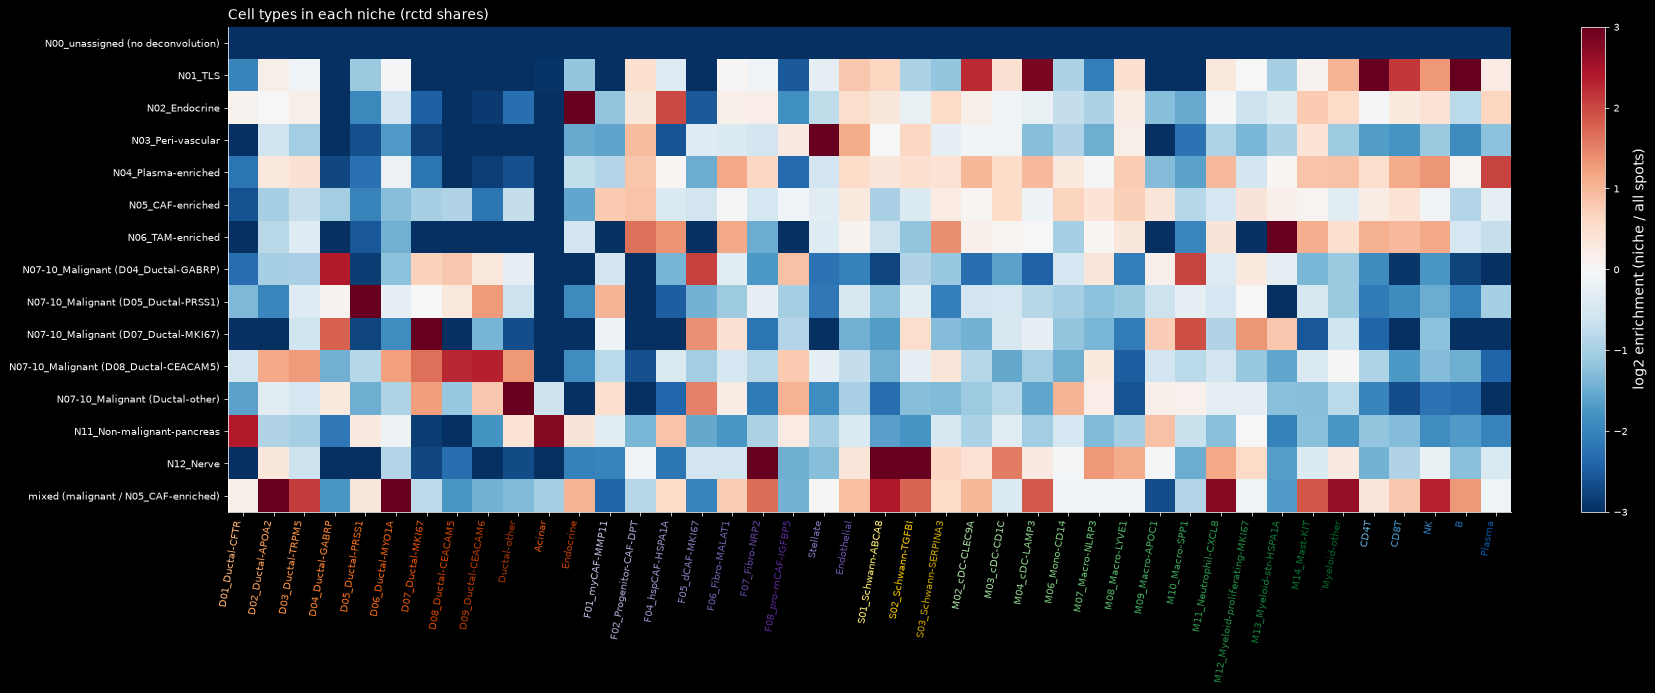

In [5]:
df_enrich_niche = scp.plot_region_celltype_heatmap(adata_vis, df_share, key='niche', figsize=(20, 7), fname=scp.fname('fig_niche_celltype'),
                                                   force=force, verbose=verbose)
plt.show()

Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_region_celltype_heatmap.png


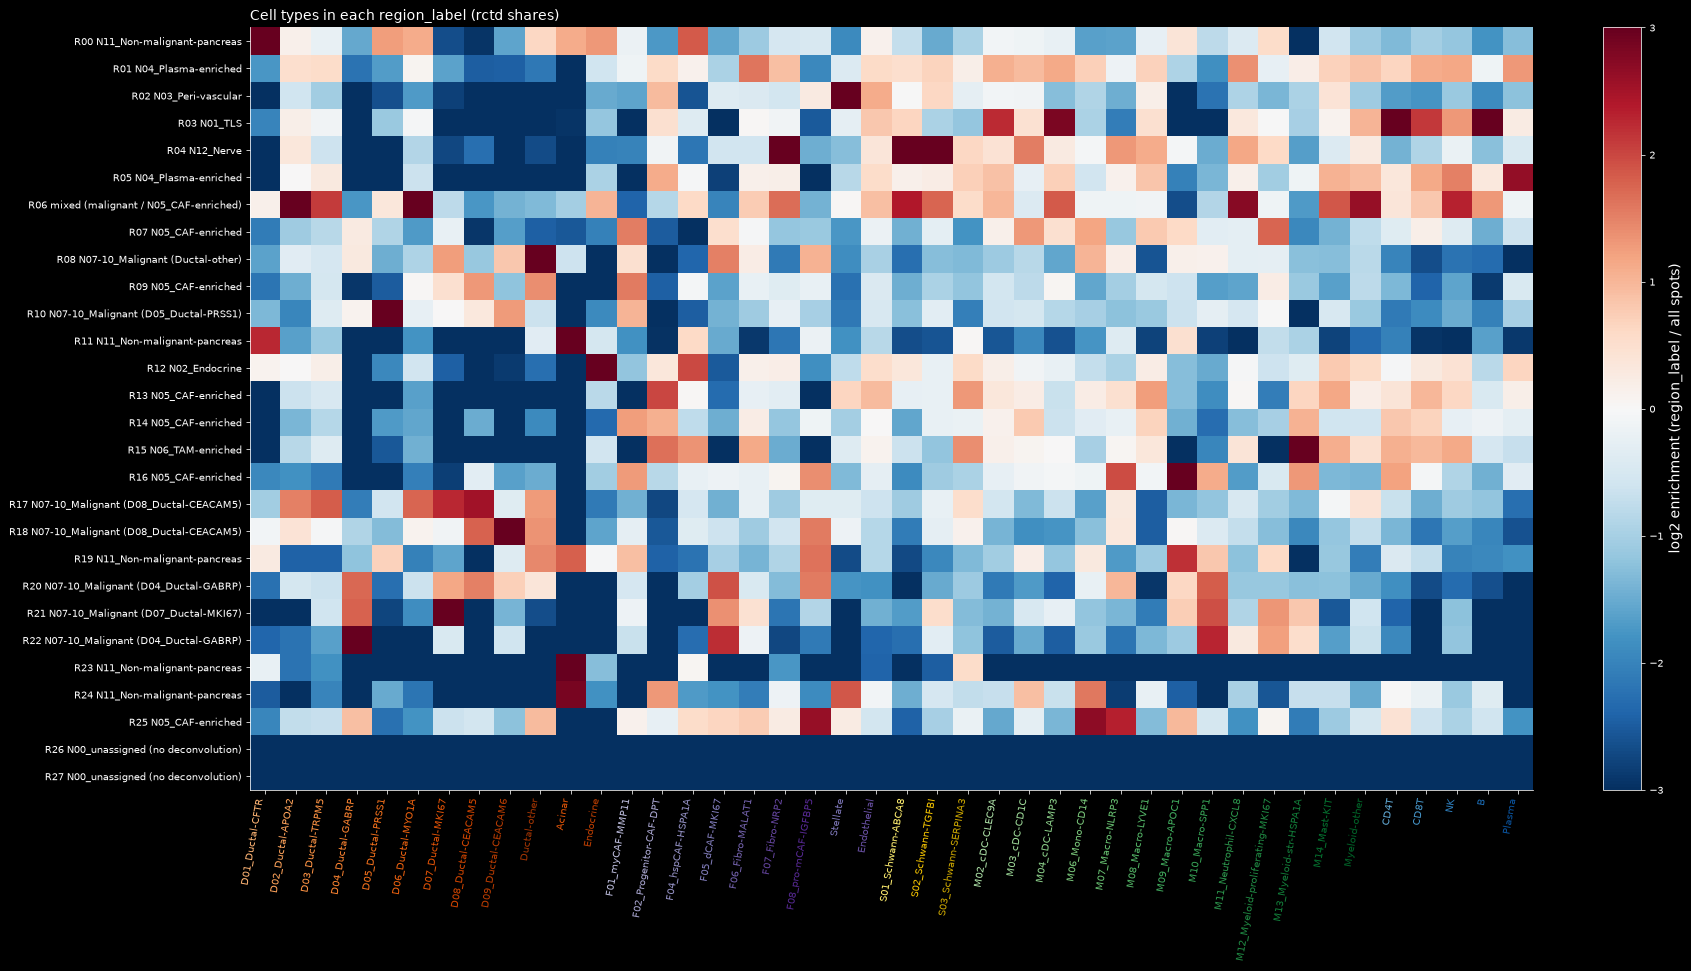

In [6]:
df_enrich = scp.plot_region_celltype_heatmap(adata_vis, df_share, key='region_label', names=names, figsize=(20, 11),
                                             fname=scp.fname('fig_region_celltype'), force=force, verbose=verbose)
plt.show()

### 4. Niches on the sections

The paper's representative section PA98 (Figure 1D right) and the other representative sections.

Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_niches_on_sections.png


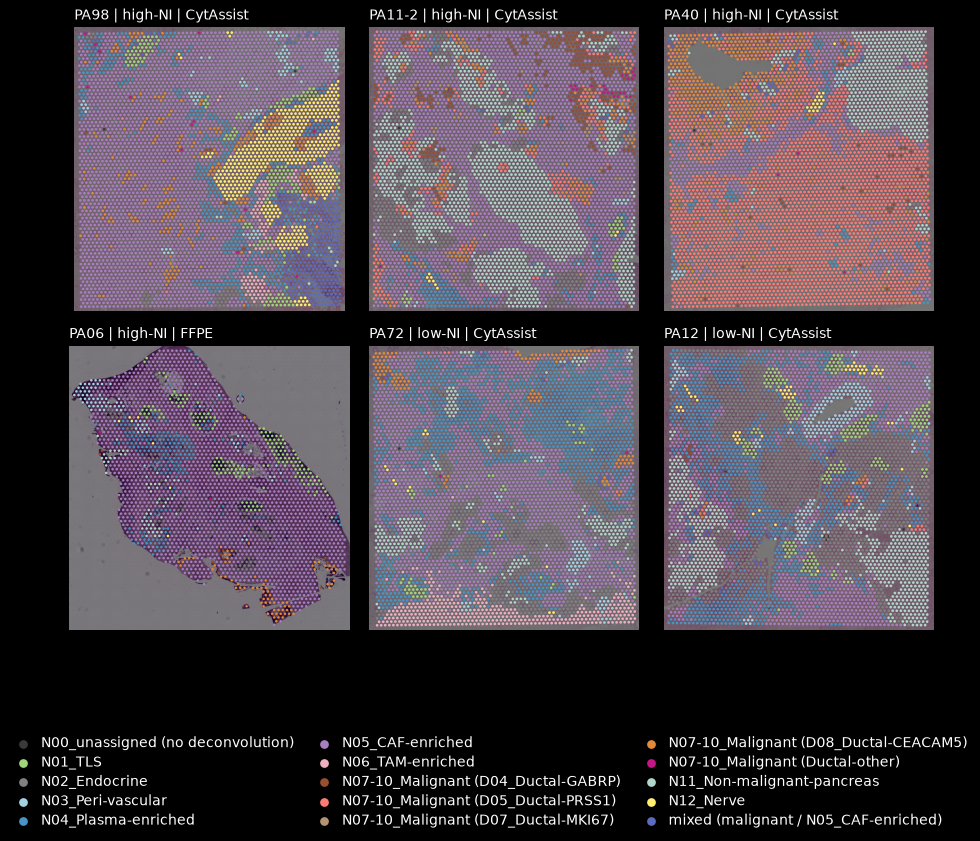

In [7]:
colors = scp.niche_colors(niches)          # the paper's niche colours (myUtiliity.R); malignant niches cycle its 4 malignant colours
fig = scp.plot_regions_on_sections(adata_vis, key='niche', sections=sections_rep, colors=colors, ncols=3, panel_size=4.2, legend_ncol=3,
                                   fname=scp.fname('fig_niches_sections'), force=force, verbose=verbose)
plt.show()

### 5. Figures 2E / 3D: niche share per section, low vs high NI

Share of each niche among the spots of a section; box + points per NI group (marker = platform), two-sided Mann-Whitney U over sections (BH FDR in the table). Paper: TLS, plasma-enriched and peri-vascular niches higher in low-NI tissues; Malignant_ductal_4 (D02_Ductal-APOA2) in low NI.

In [8]:
df_niche_sec = scp.calc_df_share_by_section(adata_vis, 'niche', fname=scp.fname('tsv_niche_by_section'), force=force, verbose=verbose)
df_t_all = scp.calc_df_ni_test(df_niche_sec, fname='tsv_niche_ni_test', force=force, verbose=verbose)
df_t_cyt = scp.calc_df_ni_test(df_niche_sec, techniques=('CytAssist',), fname='tsv_niche_ni_test_cyt', force=force, verbose=verbose)
df_t_all.merge(df_t_cyt[['group', 'log2_ratio_high_low', 'p']], on='group', suffixes=('', '_CytAssist')).sort_values('p')

Table saved ((315, 6)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_niche_share_by_section.tsv'
Table opened ((315, 6)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_niche_share_by_section.tsv'
Table saved ((15, 8)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_niche_high_vs_low_NI.tsv'
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac02_niche_high_vs_low_NI.tsv (15 rows)
Table saved ((15, 8)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_niche_high_vs_low_NI_CytAssist.tsv'
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac02_niche_high_vs_low_NI_CytAssist.tsv (15 rows)
Out[8]: 
                                    group  ...  p_CytAssist
4                     N04_Plasma-enriched  ...      0.01768
7     N07-10_Malignant (D04_Ductal-GABRP)  ...      0.03444
2                           N02_Endocrine  ...      0.03030
10  N07-10_Malignant (D08_Ductal-CEACAM5)  ...      0.04798
11        

,group,n_low,n_high,median_low,median_high,log2_ratio_high_low,p,fdr,log2_ratio_high_low_CytAssist,p_CytAssist
4,N04_Plasma-enriched,5,16,0.28414,0.01100,-3.05991,0.00118,0.01769,-2.11921,0.01768
7,N07-10_Malignant (D04_Ductal-GABRP),5,16,0.00020,0.04880,5.43241,0.00726,0.05448,4.87906,0.03444
2,N02_Endocrine,5,16,0.11787,0.00681,-2.74508,0.01176,0.05880,-2.14991,0.03030
10,N07-10_Malignant (D08_Ductal-CEACAM5),5,16,0.00247,0.04177,3.65648,0.02496,0.09362,2.17582,0.04798
11,N07-10_Malignant (Ductal-other),5,16,0.00040,0.00381,5.03751,0.05225,0.15675,0.13705,0.41598
3,N03_Peri-vascular,5,16,0.01787,0.00539,-2.42118,0.07529,0.18822,-2.28253,0.34343
14,mixed (malignant / N05_CAF-enriched),5,16,0.00556,0.00110,-3.42366,0.12612,0.22119,-2.41457,0.43182
6,N06_TAM-enriched,5,16,0.00021,0.00000,-3.40439,0.12731,0.22119,-2.29122,0.48805
9,N07-10_Malignant (D07_Ductal-MKI67),5,16,0.00000,0.00270,1.75583,0.13271,0.22119,2.59493,0.31232
1,N01_TLS,5,16,0.02595,0.00422,-0.62374,0.19913,0.29869,-0.08821,0.75505


Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_niche_share_by_NI.png
Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_niche_share_by_NI_CytAssist.png


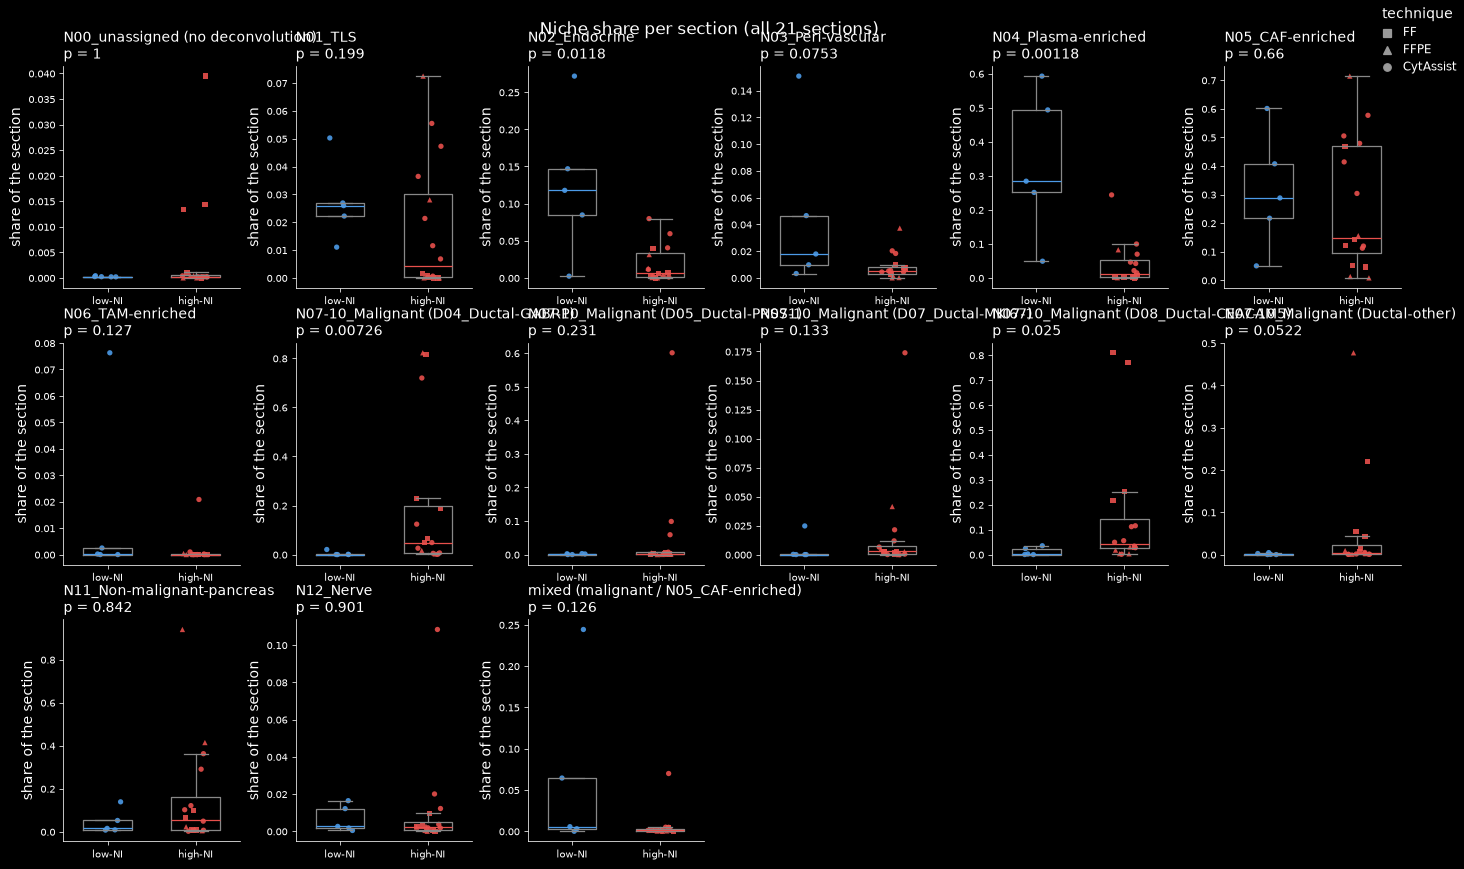

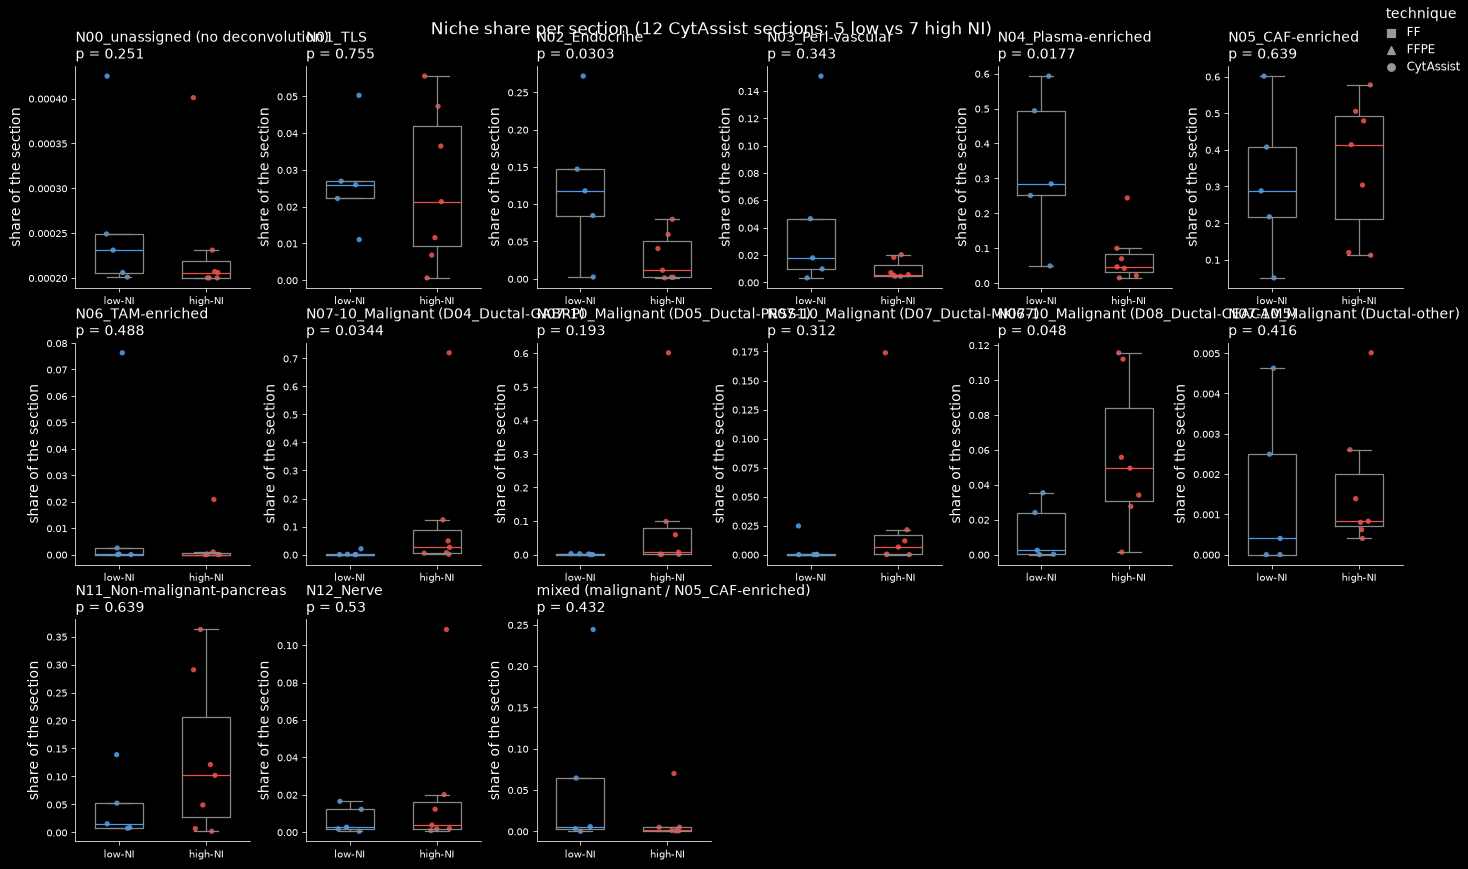

In [9]:
fig = scp.plot_ni_groups(df_niche_sec, niches, df_test=df_t_all, ncols=6, title='Niche share per section (all 21 sections)',
                         fname=scp.fname('fig_niche_ni'), force=force, verbose=verbose)
plt.show()
fig = scp.plot_ni_groups(df_niche_sec[df_niche_sec.technique == 'CytAssist'], niches, df_test=df_t_cyt, ncols=6,
                         title='Niche share per section (12 CytAssist sections: 5 low vs 7 high NI)',
                         fname=scp.fname('fig_niche_ni_cyt'), force=force, verbose=verbose)
plt.show()

### 6. Figure 3C: PCA of the sections on niche shares

Paper: the low-NI sections form a distinct cluster. Here colour = NI, marker = platform: separation along a platform axis would be technical.

Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_section_pca_niches.png
Out[10]: 
            PC1     PC2 patient ni_status  technique
section                                             
PA22    -2.6124  2.6526    PA22       low  CytAssist
PA98    -2.4963  0.6426    PA98      high  CytAssist
PA12    -2.4262  0.1112    PA12       low  CytAssist
PA06    -2.1398  1.3527    PA06      high       FFPE
PA72    -1.8674 -0.4129    PA72       low  CytAssist
PA47    -1.6997 -4.2319    PA47       low  CytAssist
PA29    -1.6167  0.1760    PA29      high  CytAssist
PA24    -1.3544 -2.1714    PA24       low  CytAssist
PA05-2  -0.8910  0.5384    PA05      high  CytAssist
PA85     0.0593  0.0227    PA85      high  CytAssist
PA11-2   0.0653  0.3009    PA11      high  CytAssist
PA02     1.1610  0.8090    PA02      high         FF
PA21     1.1836  0.3539    PA21      high  CytAssist
PA40     1.4281 -0.3470    PA40      high  CytAssist
PA04-2   1.4940  0.3063    PA04      high 

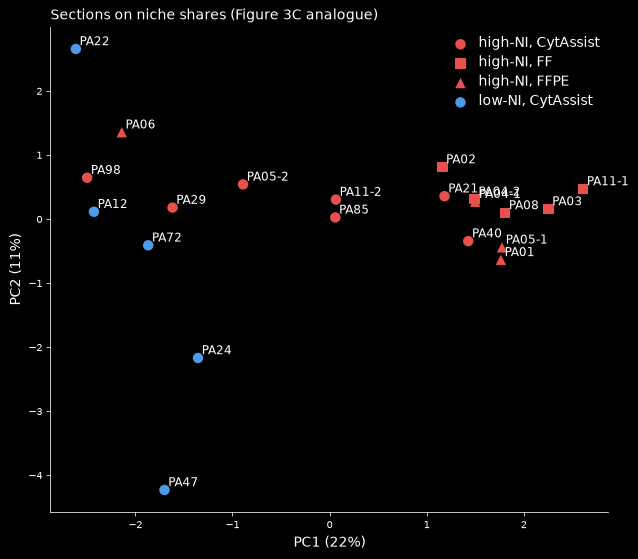

,PC1,PC2,patient,ni_status,technique
section,,,,,
PA22,-2.6124,2.6526,PA22,low,CytAssist
PA98,-2.4963,0.6426,PA98,high,CytAssist
PA12,-2.4262,0.1112,PA12,low,CytAssist
PA06,-2.1398,1.3527,PA06,high,FFPE
PA72,-1.8674,-0.4129,PA72,low,CytAssist
PA47,-1.6997,-4.2319,PA47,low,CytAssist
PA29,-1.6167,0.1760,PA29,high,CytAssist
PA24,-1.3544,-2.1714,PA24,low,CytAssist
PA05-2,-0.8910,0.5384,PA05,high,CytAssist


In [10]:
df_pca = scp.plot_section_pca(df_niche_sec, figsize=(8, 7), title='Sections on niche shares (Figure 3C analogue)',
                              fname=scp.fname('fig_section_pca'), force=force, verbose=verbose)
plt.show()
df_pca.sort_values('PC1')

### 7. Figure 3B: cell types, low vs high NI

Mean share of each cell type per section. Paper (ST): B01_naive-TCL1A, B03_GCB-RGS13 and T10_CD4_Tfh-like-CXCL13 (TLS components) higher in low NI; here B cells and T cells are major types (lymphoid subclusters were not re-derived). Also shown: plasma, NLRP3+ TAM (M07), myCAF (F01), the malignant subtypes and Schwann subsets.

In [11]:
df_ct_sec = scp.calc_df_celltype_by_section(adata_vis, df_abund, fname=scp.fname('tsv_celltype_by_section'), force=force, verbose=verbose)
df_ct_all = scp.calc_df_ni_test(df_ct_sec, group_col='cell_type', fname='tsv_celltype_ni_test', force=force, verbose=verbose)
df_ct_cyt = scp.calc_df_ni_test(df_ct_sec, group_col='cell_type', techniques=('CytAssist',), fname='tsv_celltype_ni_test_cyt', force=force, verbose=verbose)
df_ct_all.merge(df_ct_cyt[['cell_type', 'log2_ratio_high_low', 'p']], on='cell_type', suffixes=('', '_CytAssist')).sort_values('p').head(25)

Table saved ((882, 7)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_share_by_section.tsv'
Table opened ((882, 7)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_share_by_section.tsv'
Table saved ((42, 8)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_high_vs_low_NI.tsv'
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_high_vs_low_NI.tsv (42 rows)
Table saved ((42, 8)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_high_vs_low_NI_CytAssist.tsv'
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_high_vs_low_NI_CytAssist.tsv (42 rows)
Out[11]: 
                 cell_type  n_low  ...  log2_ratio_high_low_CytAssist  p_CytAssist
41                  Plasma      5  ...                       -1.63554      0.01768
39                      NK      5  ...                       -1.55465      0.01768
35            M14_Mast-KIT      5  ...    

,cell_type,n_low,n_high,median_low,median_high,log2_ratio_high_low,p,fdr,log2_ratio_high_low_CytAssist,p_CytAssist
41,Plasma,5,16,0.07908,0.01311,-2.32727,0.00069,0.00871,-1.63554,0.01768
39,NK,5,16,0.00805,0.00146,-2.13761,0.00069,0.00871,-1.55465,0.01768
35,M14_Mast-KIT,5,16,0.00937,0.00192,-1.91269,0.00110,0.00871,-1.67305,0.00253
29,M08_Macro-LYVE1,5,16,0.09097,0.02075,-1.44707,0.00118,0.00871,-0.64829,0.03030
36,Myeloid-other,5,16,0.00645,0.00160,-1.64318,0.00187,0.00871,-1.50779,0.01768
9,Ductal-other,5,16,0.00433,0.02962,3.26137,0.00187,0.00871,1.73863,0.04798
21,S01_Schwann-ABCA8,5,16,0.01175,0.00278,-1.18628,0.00187,0.00871,-0.26178,0.04798
20,Endothelial,5,16,0.08083,0.03154,-1.01319,0.00187,0.00871,-0.69982,0.01768
38,CD8T,5,16,0.00974,0.00264,-1.61468,0.00187,0.00871,-1.23358,0.01010
30,M09_Macro-APOC1,5,16,0.00786,0.01382,1.20268,0.00413,0.01576,0.61017,0.03030


Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_celltype_share_by_NI.png


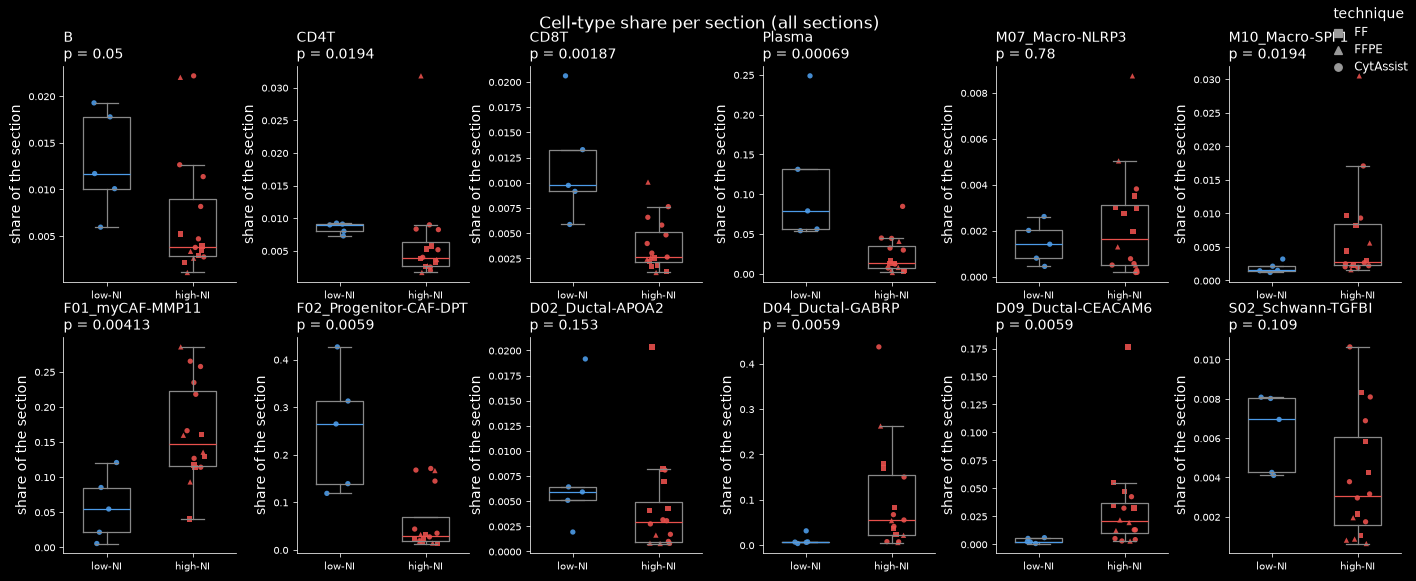

In [12]:
cts = ['B', 'CD4T', 'CD8T', 'Plasma', 'M07_Macro-NLRP3', 'M10_Macro-SPP1', 'F01_myCAF-MMP11', 'F02_Progenitor-CAF-DPT',
       'D02_Ductal-APOA2', 'D04_Ductal-GABRP', 'D09_Ductal-CEACAM6', 'S02_Schwann-TGFBI']
fig = scp.plot_ni_groups(df_ct_sec, cts, group_col='cell_type', df_test=df_ct_all, ncols=6, title='Cell-type share per section (all sections)',
                         fname=scp.fname('fig_celltype_ni'), force=force, verbose=verbose)
plt.show()

### 8. Malignant subtypes: pure spots (Figure 2C), composition and diversity (Figure 2J)

**Pure spots**: share of one malignant subtype >= 0.8 of the spot (the paper's criterion on its RCTD proportions); shown on the H&E of the section with most such spots. **Composition**: malignant subtypes (D02-D09) as a share of the malignant cells of each section, with the Shannon index. Paper: lower diversity in high-NI tissues; D02_Ductal-APOA2 in low NI.

D02_Ductal-APOA2        0
D03_Ductal-TRPM5        0
D04_Ductal-GABRP      200
D05_Ductal-PRSS1        2
D06_Ductal-MYO1A        0
D07_Ductal-MKI67        1
D08_Ductal-CEACAM5     23
D09_Ductal-CEACAM6      0
Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_malignant_pure_spots_D08.png
Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_malignant_pure_spots_D04.png


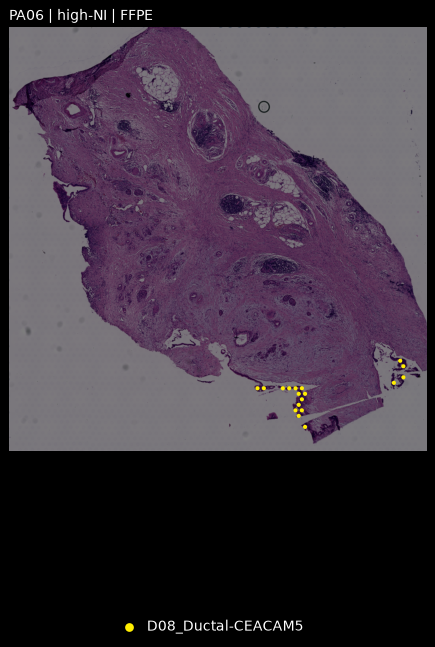

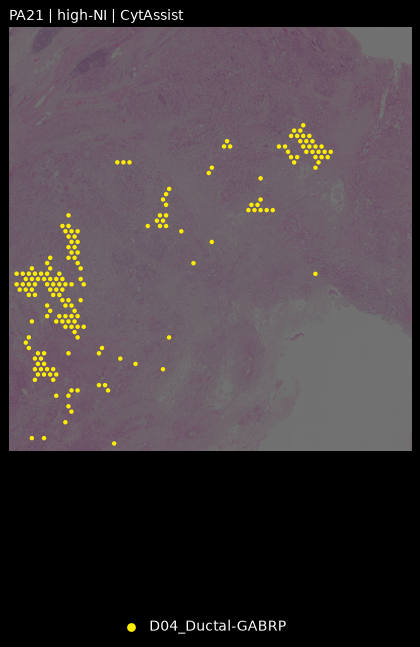

In [13]:
mal = [c for c in df_share.columns if c[:3] in ('D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09')]
pure = (df_share[mal] >= 0.8)
print(pure.sum().to_string())
for sub in ['D08_Ductal-CEACAM5', 'D09_Ductal-CEACAM6', 'D04_Ductal-GABRP', 'D02_Ductal-APOA2']:
    if sub in pure and pure[sub].any():
        lib = adata_vis.obs.loc[pure[sub].values, 'section'].value_counts().index[0]
        adata_vis.obs['_pure'] = np.where(pure[sub].values, sub, '')
        fig = scp.plot_regions_on_sections(adata_vis, key='_pure', sections=[lib], colors={sub: '#FFEE00'}, ncols=1, panel_size=6,
                                           fname=scp.fname('fig_malignant_pure', sub=sub.split('_')[0]), force=force, verbose=verbose)
        plt.show()

Table saved ((21, 12)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_malignant_composition_by_section.tsv'
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac02_malignant_composition_by_section.tsv (21 rows)
Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_malignant_composition_shannon.png
Out[14]: 
    sections  n_low  n_high  median_low  median_high       p
0        all      5      16       1.976       1.3644  0.0001
1  CytAssist      5       7       1.976       1.4617  0.0025


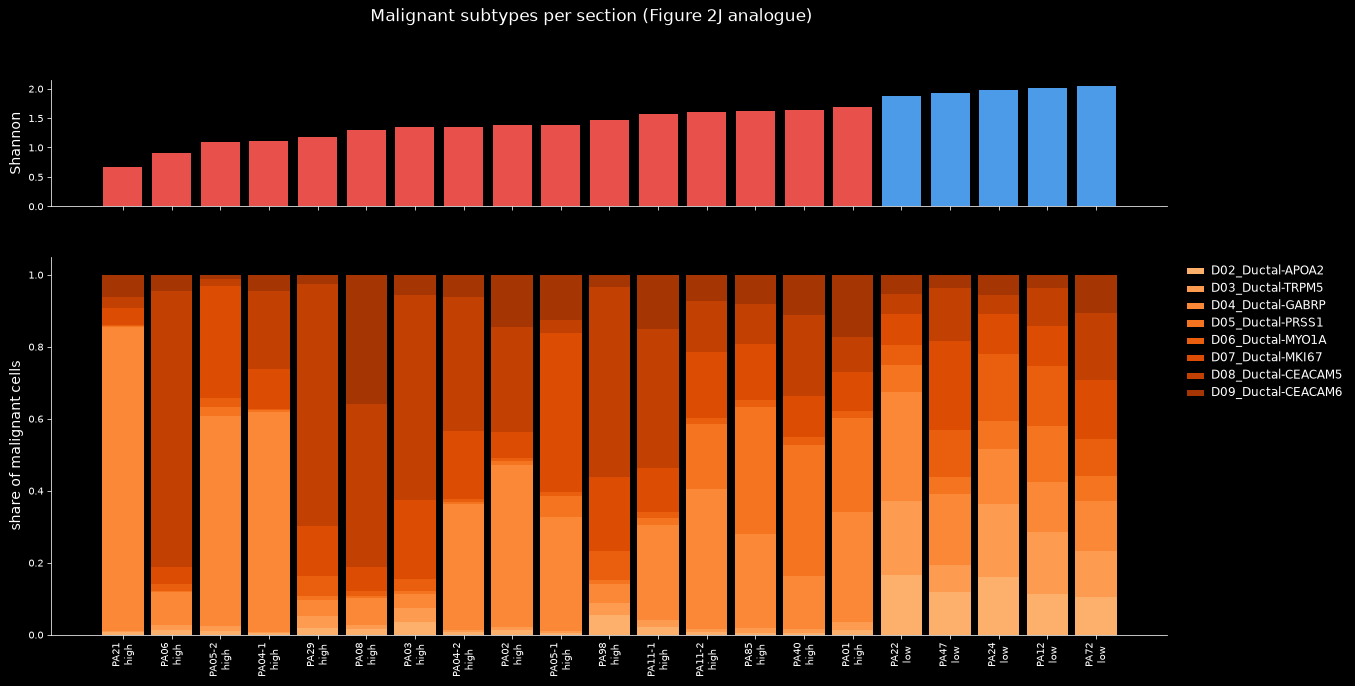

,sections,n_low,n_high,median_low,median_high,p
0,all,5,16,1.976,1.3644,0.0001
1,CytAssist,5,7,1.976,1.4617,0.0025


In [14]:
df_div = scp.calc_df_malignant_diversity(adata_vis, df_abund, fname='tsv_malignant_diversity', force=force, verbose=verbose)
fig = scp.plot_malignant_diversity(df_div, fname='fig_malignant_comp', force=force, verbose=verbose)
plt.show()
scp.calc_df_diversity_test(df_div)

### 9. Co-occurrence of cell types across sections (Figure 3I analogue)

Spearman correlation of the mean cell-type shares over the 21 sections; pairs with rho > 0.6 (the paper's threshold; the paper used sc/sn proportions per sample). Paper: M07_Macro-NLRP3 with T11_CD4_Th17-like (not separated here).

Table saved ((136, 3)) at '/home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_cooccurrence.tsv'
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac02_celltype_cooccurrence.tsv (136 rows)
Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_celltype_cooccurrence.png
Out[15]: 
         cell_type_1             cell_type_2       rho
0     M02_cDC-CLEC9A           M04_cDC-LAMP3  0.927273
1   D03_Ductal-TRPM5           Myeloid-other  0.927273
2                 NK       S01_Schwann-ABCA8  0.901299
3     M02_cDC-CLEC9A                      NK  0.872727
4                  B                    CD4T  0.871429
5   D02_Ductal-APOA2        D03_Ductal-TRPM5  0.871429
6     M02_cDC-CLEC9A       S01_Schwann-ABCA8  0.863636
7      M04_cDC-LAMP3       S01_Schwann-ABCA8  0.851948
8        Endothelial          M02_cDC-CLEC9A  0.848052
9      Myeloid-other                      NK  0.846753
10              CD8T          M02_cDC-CLEC9A  0.840260
11      

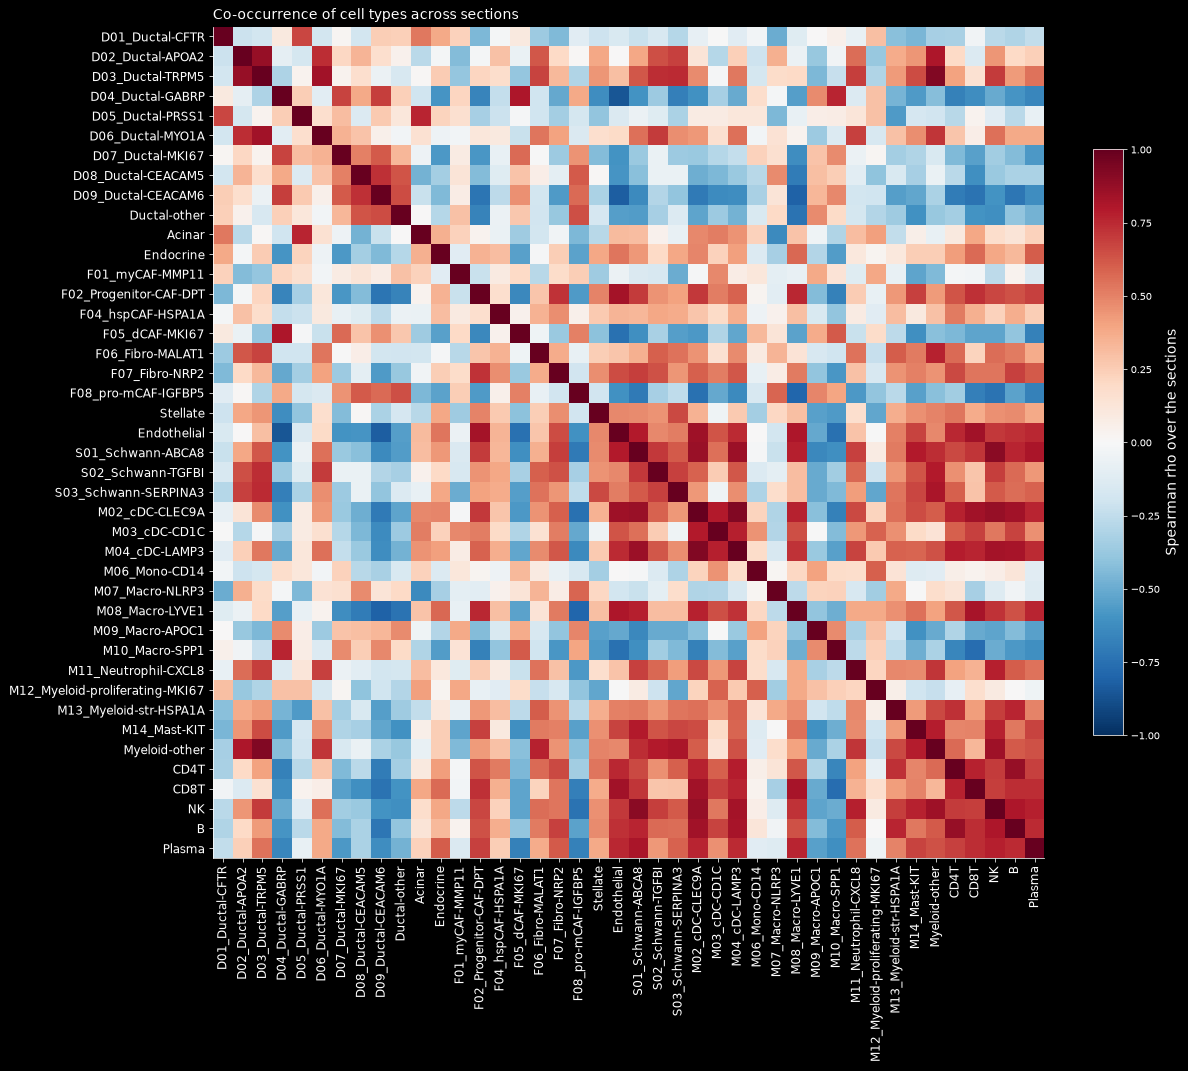

,cell_type_1,cell_type_2,rho
0,M02_cDC-CLEC9A,M04_cDC-LAMP3,0.927273
1,D03_Ductal-TRPM5,Myeloid-other,0.927273
2,NK,S01_Schwann-ABCA8,0.901299
3,M02_cDC-CLEC9A,NK,0.872727
4,B,CD4T,0.871429
5,D02_Ductal-APOA2,D03_Ductal-TRPM5,0.871429
6,M02_cDC-CLEC9A,S01_Schwann-ABCA8,0.863636
7,M04_cDC-LAMP3,S01_Schwann-ABCA8,0.851948
8,Endothelial,M02_cDC-CLEC9A,0.848052
9,Myeloid-other,NK,0.846753


In [15]:
R = scp.calc_df_celltype_correlation(df_ct_sec)
pairs = scp.calc_df_cooccurrence(R, min_rho=0.6, fname='tsv_cooccurrence', force=force, verbose=verbose)
fig = scp.plot_cooccurrence(R, fname='fig_cooccurrence', force=force, verbose=verbose)
plt.show()
pairs.head(30)

### 10. PDAC / NI genes per region; NI-related gene score

Dot plot of the 24 genes of **PDAC_GENES** per region (fraction of spots > 0; mean log1p(CP10k) / max over the regions). **NI score** (Figure 2M on the spots): mean z (within section) of the 34 NI-related genes of the paper (**PDAC_NI_GENES**; those measured by the three panels), averaged per region.

Saving figure to /home/flavio/uv/cell_cell_communication/pdac/figures/pdac02_region_gene_dotplot.png


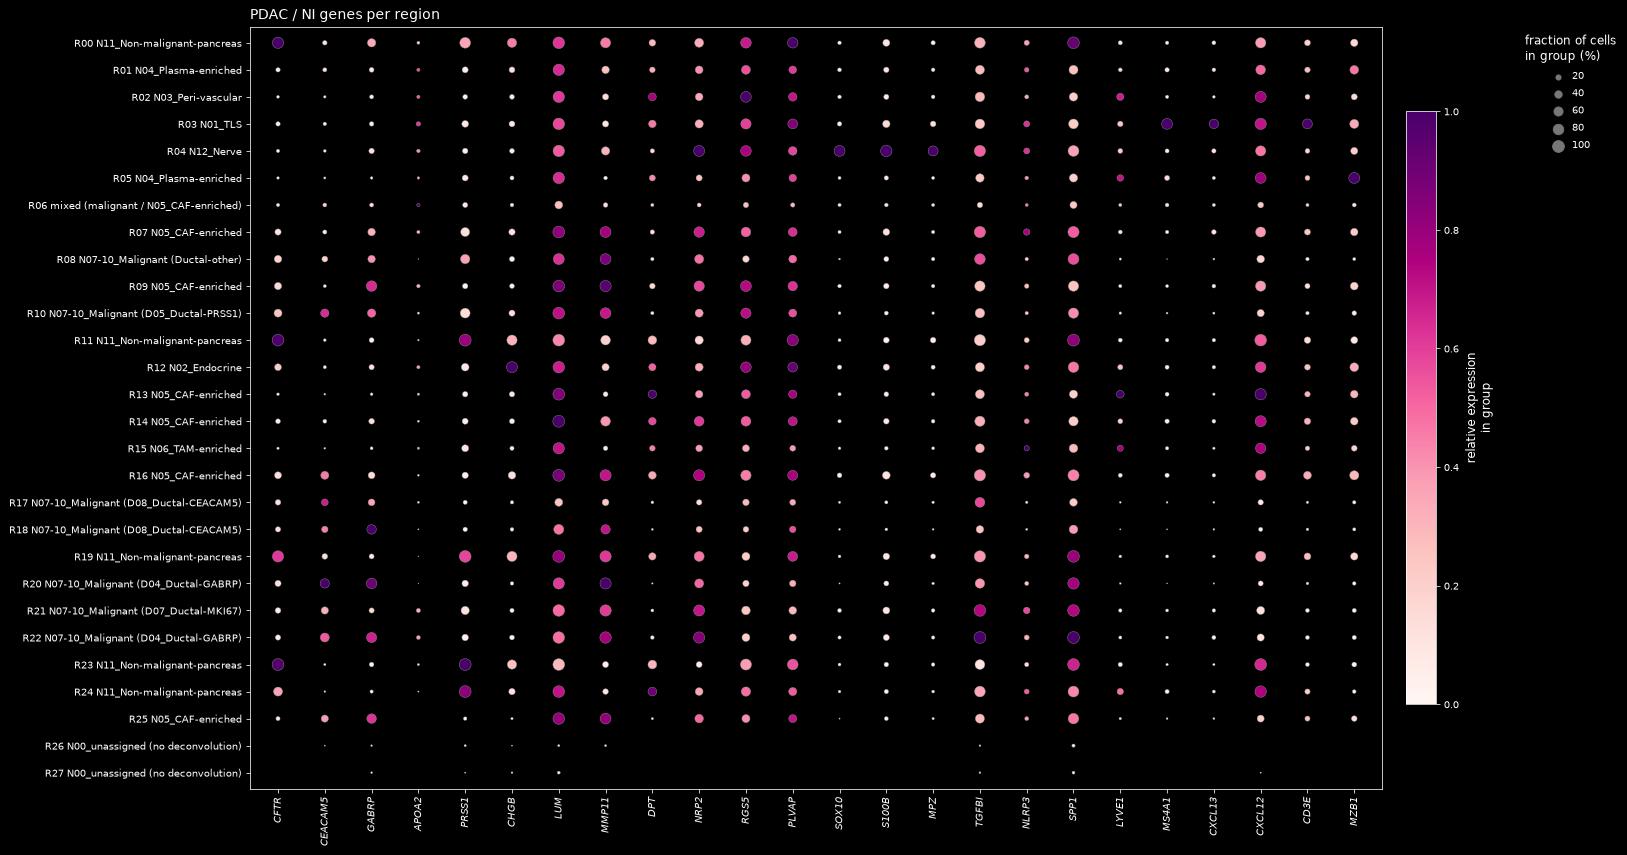

In [16]:
order = [r for r in regions]
df_frac, df_mean, df_rel = scp.calc_df_dotplot(list(PDAC_GENES), 'region_label', adata_vis[:, adata_vis.var.in_all_panels.values], order=order)
fig = scp.plot_dotplot(df_frac, df_rel, row_labels={r: f"{r} {names.get(r, '')}" for r in order}, cmap='RdPu', figsize=(17, 11),
                       title='PDAC / NI genes per region', fname=scp.fname('fig_region_genes'), force=force, verbose=verbose)
plt.show()

In [17]:
ni_score = scp.nerve_marker_score(adata_vis[:, adata_vis.var.in_all_panels.values], genes=PDAC_NI_GENES)
adata_vis.obs['NI_gene_score'] = ni_score
df_ni = adata_vis.obs.groupby('region_label', observed=True).NI_gene_score.agg(['mean', 'median', 'size']).assign(niche=lambda d: d.index.map(names))
df_ni.sort_values('mean', ascending=False).round(3)

Out[17]: 
               mean  median  size                                  niche
region_label                                                            
R04           0.309   0.293   952                              N12_Nerve
R03           0.281   0.274  1768                                N01_TLS
R19           0.062   0.052  2427             N11_Non-malignant-pancreas
R00           0.045   0.033  3802             N11_Non-malignant-pancreas
R25           0.044   0.012  1481                       N05_CAF-enriched
R24           0.032   0.019   897             N11_Non-malignant-pancreas
R02           0.032   0.021  1536                      N03_Peri-vascular
R13           0.021   0.013  8033                       N05_CAF-enriched
R08           0.015  -0.012  1947        N07-10_Malignant (Ductal-other)
R14           0.005  -0.003  3147                       N05_CAF-enriched
R01           0.003  -0.004  6036                    N04_Plasma-enriched
R16          -0.001   0.008  1425        

,mean,median,size,niche
region_label,,,,
R04,0.309,0.293,952,N12_Nerve
R03,0.281,0.274,1768,N01_TLS
R19,0.062,0.052,2427,N11_Non-malignant-pancreas
R00,0.045,0.033,3802,N11_Non-malignant-pancreas
R25,0.044,0.012,1481,N05_CAF-enriched
R24,0.032,0.019,897,N11_Non-malignant-pancreas
R02,0.032,0.021,1536,N03_Peri-vascular
R13,0.021,0.013,8033,N05_CAF-enriched
R08,0.015,-0.012,1947,N07-10_Malignant (Ductal-other)


### 11. Interactive region maps

Hover: niche, top cell types. One HTML per representative section in **pdac/figures** (**pdac02_region_map_<section>.html**); PA98 is shown.

In [18]:
hover = {r: f"{row.top_share}" for r, row in df_region_summary.set_index('region_label').iterrows()}
for lib in sections_rep:
    fig = scp.plotly_spatial_visium(names, adata_vis, key='region_label', library_id=lib, hover_extra=hover, fontsize_title=20,
                                    fontsize_legend=12, fontsize_hover=13, marker_line_color="#222222", fname='fig_region_map',
                                    force=force, verbose=False)
    if lib == scp.params['library_main']:
        fig.show()

### Notes for interpretation

- **Confound**: read the CytAssist-only columns before the all-section ones; the platform changes depth, gene panel and the deconvolution.
- **Sections, not patients**: 21 sections of 17 patients (two sections for PA04, PA05, PA11).
- **TLS**: B / T cells are major types here; the TLS niche is defined by co-occurring B and T cells, not by GC B or Tfh states.
- **Malignant niches** are numbered by dominant subtype, not by the paper's (unpublished) assignment.